<a href="https://colab.research.google.com/github/gerardagustina/breast-cancer-detection/blob/main/notebooks/03_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Breast Cancer Detection — 03. Model & Training
**Goal:** Build a DenseNet121 classifier with transfer learning, train it and evaluate it.

In [2]:
!pip install -q medmnist monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 5.0 MB/s eta 0:00:00


In [3]:
from monai.utils import set_determinism
set_determinism(seed=42)   # fija la aleatoriedad: mismos resultados en cada ejecución

import medmnist, torch
from medmnist import BreastMNIST
from monai.data import set_track_meta, ArrayDataset, DataLoader
from monai.transforms import (Compose, EnsureChannelFirst, ScaleIntensityRange,
                              RandFlip, RandRotate, RandZoom)
set_track_meta(False)

splits = {s: BreastMNIST(split=s, download=True, size=224) for s in ["train", "val", "test"]}

base = [EnsureChannelFirst(channel_dim="no_channel"),
        ScaleIntensityRange(a_min=0, a_max=255, b_min=0, b_max=1, clip=True)]
train_tf = Compose(base + [RandFlip(prob=0.5, spatial_axis=1),
                           RandRotate(range_x=0.26, prob=0.5),
                           RandZoom(min_zoom=0.9, max_zoom=1.1, prob=0.5)])
val_tf = Compose(base)

def make_ds(split, tf):
    d = splits[split]
    return ArrayDataset(img=d.imgs, img_transform=tf, labels=d.labels.ravel())

train_loader = DataLoader(make_ds("train", train_tf), batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(make_ds("val",   val_tf),   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(make_ds("test",  val_tf),   batch_size=32, shuffle=False, num_workers=2)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Datos listos ✅ | device:", device)

100%|██████████| 30.9M/30.9M [00:26<00:00, 1.15MB/s]


Datos listos ✅ | device: cuda


In [4]:
import torch.nn as nn
from torchvision.models import densenet121, DenseNet121_Weights

class BreastNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)   # pesos de ImageNet
        self.net.classifier = nn.Linear(self.net.classifier.in_features, 1)  # 1000 clases → 1 salida

    def forward(self, x):
        x = x.repeat(1, 3, 1, 1)          # gris (1 canal) → 3 canales, como espera ImageNet
        return self.net(x).squeeze(1)     # (32, 1) → (32,)

model = BreastNet().to(device)

print(f"Pesos totales: {sum(p.numel() for p in model.parameters()):,}")
x, y = next(iter(train_loader))
print("Entrada:", x.shape, "→ Salida:", model(x.to(device)).shape)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 112MB/s]


Pesos totales: 6,954,881
Entrada: torch.Size([32, 1, 224, 224]) → Salida: torch.Size([32])


## Model architecture
- **DenseNet121** (torchvision) initialised with **ImageNet weights** (transfer learning).
- Classifier head replaced: 1000 ImageNet classes → **1 output (logit)**.
- Grayscale input replicated to 3 channels to match the pretrained network.
- **6.95M parameters.** Dense connectivity enables feature reuse with few parameters,
  reducing overfitting on a small dataset (546 training images).

## Training

In [5]:
labels_train = splits["train"].labels.ravel()
n_mal = (labels_train == 0).sum()   # 147 malignos
n_ben = (labels_train == 1).sum()   # 399 normales/benignos

pos_weight = torch.tensor([n_ben / n_mal], dtype=torch.float32, device=device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print("Peso de la clase maligna:", round(pos_weight.item(), 2))

Peso de la clase maligna: 2.71


In [6]:
from sklearn.metrics import roc_auc_score

def run_epoch(loader, train):
    model.train() if train else model.eval()
    total_loss, probs, ys = 0.0, [], []

    with torch.set_grad_enabled(train):
        for x, y in loader:
            x = x.to(device)
            y = (1 - y).float().to(device)       # invertimos: 1 = maligno, 0 = normal/benigno

            logits = model(x)                    # 1. predice
            loss = loss_fn(logits, y)            # 2. mide el error

            if train:
                optimizer.zero_grad()            # 3. borra los gradientes anteriores
                loss.backward()                  # 4. calcula los gradientes
                optimizer.step()                 # 5. ajusta los pesos

            total_loss += loss.item() * len(y)
            probs += torch.sigmoid(logits).detach().cpu().tolist()
            ys += y.cpu().tolist()

    return total_loss / len(ys), roc_auc_score(ys, probs)

print("Función lista ✅")

Función lista ✅


In [7]:
EPOCHS, PATIENCE = 30, 5
best_auc, wait, history = 0.0, 0, []

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_auc = run_epoch(train_loader, train=True)    # aprende
    va_loss, va_auc = run_epoch(val_loader, train=False)     # mide
    history.append((tr_loss, va_loss, tr_auc, va_auc))

    print(f"Época {epoch:2d} | train loss {tr_loss:.3f} AUC {tr_auc:.3f} "
          f"| val loss {va_loss:.3f} AUC {va_auc:.3f}")

    if va_auc > best_auc:                                     # ¿mejor val hasta ahora?
        best_auc, wait = va_auc, 0
        torch.save(model.state_dict(), "best_model.pt")       # guardar los pesos
        print("   ↑ nuevo mejor modelo guardado")
    else:
        wait += 1
        if wait >= PATIENCE:                                  # 5 épocas sin mejorar
            print(f"Early stopping en la época {epoch}")
            break

print(f"\nMejor AUC en val: {best_auc:.3f}")

Época  1 | train loss 0.873 AUC 0.759 | val loss 0.829 AUC 0.905
   ↑ nuevo mejor modelo guardado
Época  2 | train loss 0.597 AUC 0.903 | val loss 0.554 AUC 0.951
   ↑ nuevo mejor modelo guardado
Época  3 | train loss 0.387 AUC 0.969 | val loss 0.427 AUC 0.963
   ↑ nuevo mejor modelo guardado
Época  4 | train loss 0.288 AUC 0.983 | val loss 0.312 AUC 0.974
   ↑ nuevo mejor modelo guardado
Época  5 | train loss 0.212 AUC 0.992 | val loss 0.234 AUC 0.983
   ↑ nuevo mejor modelo guardado
Época  6 | train loss 0.177 AUC 0.992 | val loss 0.298 AUC 0.977
Época  7 | train loss 0.115 AUC 0.998 | val loss 0.326 AUC 0.977
Época  8 | train loss 0.096 AUC 0.998 | val loss 0.262 AUC 0.986
   ↑ nuevo mejor modelo guardado
Época  9 | train loss 0.140 AUC 0.994 | val loss 0.450 AUC 0.968
Época 10 | train loss 0.092 AUC 0.999 | val loss 0.323 AUC 0.979
Época 11 | train loss 0.083 AUC 0.999 | val loss 0.309 AUC 0.980
Época 12 | train loss 0.056 AUC 1.000 | val loss 0.320 AUC 0.982
Época 13 | train loss 

In [8]:
import numpy as np

model.load_state_dict(torch.load("best_model.pt"))   # recupera los pesos de la mejor época
model.eval()

probs, ys = [], []
with torch.no_grad():                                 # sin gradientes: solo predecir
    for x, y in test_loader:
        probs += torch.sigmoid(model(x.to(device))).cpu().tolist()
        ys += (1 - y).tolist()                        # invertimos: 1 = maligno

probs, ys = np.array(probs), np.array(ys)
print("Imágenes de test:", len(ys), "| malignas:", int(ys.sum()))
print("AUC en TEST:", round(roc_auc_score(ys, probs), 3))

Imágenes de test: 156 | malignas: 42
AUC en TEST: 0.937


Umbral: 0.5
  TP (cánceres detectados):     33
  FN (cánceres NO detectados):  9
  FP (falsas alarmas):          9
  TN (benignos bien descartados): 105
Sensibilidad: 0.786 | Especificidad: 0.921


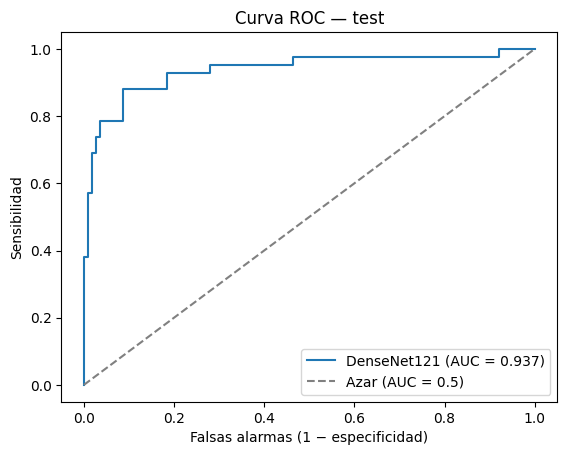

In [9]:
from sklearn.metrics import confusion_matrix, roc_curve
import matplotlib.pyplot as plt

umbral = 0.5
pred = (probs >= umbral).astype(int)                 # probabilidad → decisión (0 o 1)
tn, fp, fn, tp = confusion_matrix(ys, pred).ravel()

print(f"Umbral: {umbral}")
print(f"  TP (cánceres detectados):     {tp}")
print(f"  FN (cánceres NO detectados):  {fn}")
print(f"  FP (falsas alarmas):          {fp}")
print(f"  TN (benignos bien descartados): {tn}")
print(f"Sensibilidad: {tp/(tp+fn):.3f} | Especificidad: {tn/(tn+fp):.3f}")

fpr, tpr, _ = roc_curve(ys, probs)
plt.plot(fpr, tpr, label=f"DenseNet121 (AUC = {roc_auc_score(ys, probs):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
plt.xlabel("Falsas alarmas (1 − especificidad)"); plt.ylabel("Sensibilidad")
plt.title("Curva ROC — test"); plt.legend(); plt.show()

In [10]:
def predict(loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for x, y in loader:
            probs += torch.sigmoid(model(x.to(device))).cpu().tolist()
            ys += (1 - y).tolist()
    return np.array(probs), np.array(ys)

# 1) Elegir el umbral en VAL
val_probs, val_ys = predict(val_loader)
fpr_v, tpr_v, thr_v = roc_curve(val_ys, val_probs)
umbral_clin = thr_v[np.argmax(tpr_v >= 1.0)]      # detectar el 100 % de las malignas de val
print("Umbral elegido en VAL:", round(umbral_clin, 3))

# 2) Aplicarlo a TEST
pred = (probs >= umbral_clin).astype(int)
tn, fp, fn, tp = confusion_matrix(ys, pred).ravel()
print(f"TEST → TP {tp} | FN {fn} | FP {fp} | TN {tn}")
print(f"Sensibilidad: {tp/(tp+fn):.3f} | Especificidad: {tn/(tn+fp):.3f}")

Umbral elegido en VAL: 0.12
TEST → TP 39 | FN 3 | FP 21 | TN 93
Sensibilidad: 0.929 | Especificidad: 0.816


## Results (test set, seed 42)
| Metric | Threshold 0.5 | Clinical threshold 0.12 (selected on val) |
|---|---|---|
| AUC | 0.937 | 0.937 |
| Sensitivity | 78.6% (33/42) | **92.9% (39/42)**, 95% CI ≈ 81–98% |
| Specificity | 92.1% (105/114) | 81.6% (93/114) |

- Validation AUC (0.986) > test AUC (0.937): expected optimism from selecting the best epoch on a small validation set.
- Lowering the threshold detects 6 more cancers at the cost of 12 more false alarms, a reasonable trade-off for screening.
- **Limitation:** the clinical threshold was unstable across random seeds (0.12–0.40), since the validation set has only 21 malignant cases. Cross-validation is the recommended next step.

¿Mismas salidas? True


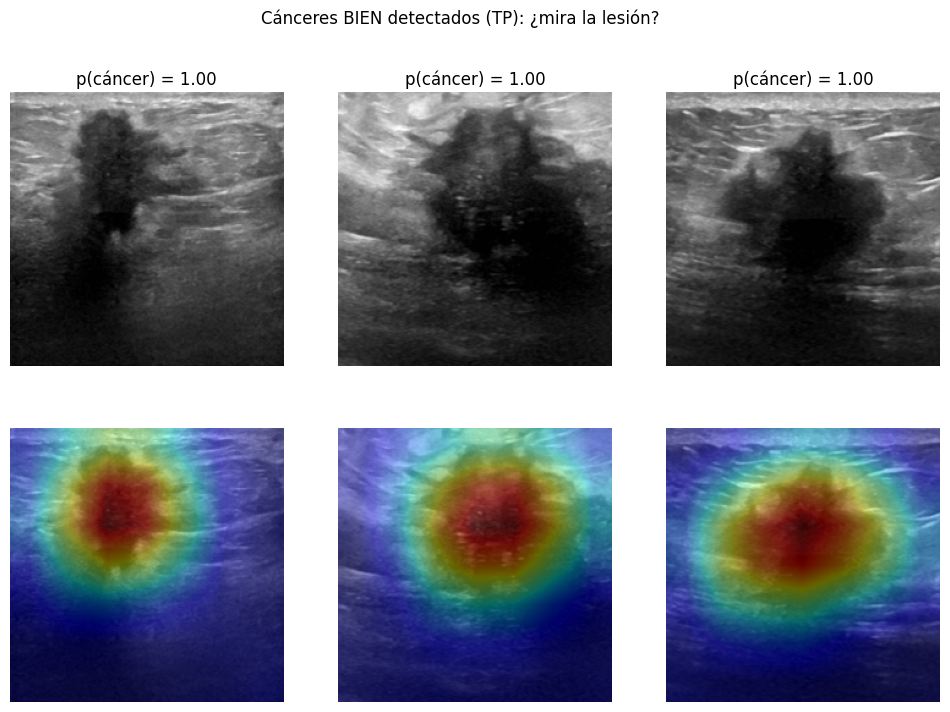

In [11]:
from monai.visualize import GradCAM

class CamWrapper(nn.Module):
    """Reproduce el forward de DenseNet con una ReLU no in-place, para que Grad-CAM pueda escucharla."""
    def __init__(self, m):
        super().__init__()
        self.features = m.net.features            # el cuerpo (mismos pesos, no se copian)
        self.relu = nn.ReLU(inplace=False)        # la ReLU final, ahora "escuchable"
        self.classifier = m.net.classifier        # la cabeza (mismos pesos)
    def forward(self, x):
        x = x.repeat(1, 3, 1, 1)                                    # gris → 3 canales
        f = self.relu(self.features(x))                             # 1024 mapas de 7×7, todos ≥ 0
        f = nn.functional.adaptive_avg_pool2d(f, 1).flatten(1)     # resumen: 1024 números
        return self.classifier(f)                                   # (N, 1)

for mod in model.modules():          # quita los hooks de los intentos anteriores
    mod._forward_hooks.clear()
    mod._backward_hooks.clear()

wrapper = CamWrapper(model).eval()
def minmax(x):                                         # escala cada mapa a [0, 1] SIN invertir
    x = x - x.amin(dim=(2, 3), keepdim=True)           # el mínimo pasa a 0
    return x / (x.amax(dim=(2, 3), keepdim=True) + 1e-8)  # el máximo pasa a 1

cam = GradCAM(nn_module=wrapper, target_layers="relu", postprocessing=minmax)

# Comprobación: el adaptador debe dar EXACTAMENTE lo mismo que nuestro modelo
with torch.no_grad():
    xb, _ = next(iter(test_loader))
    xb = xb.to(device)
    print("¿Mismas salidas?", torch.allclose(model(xb), wrapper(xb).squeeze(1), atol=1e-5))

def show_cam(indices, titulo):
    fig, ax = plt.subplots(2, len(indices), figsize=(4 * len(indices), 8), squeeze=False)
    for j, i in enumerate(indices):
        img = val_tf(splits["test"].imgs[i]).unsqueeze(0).to(device)    # (1, 1, 224, 224)
        heat = cam(x=img, class_idx=0)[0, 0].detach().cpu()
        ax[0, j].imshow(img[0, 0].cpu(), cmap="gray")
        ax[0, j].set_title(f"p(cáncer) = {probs[i]:.2f}")
        ax[1, j].imshow(img[0, 0].cpu(), cmap="gray")
        ax[1, j].imshow(heat, cmap="jet", alpha=0.4)
        ax[0, j].axis("off"); ax[1, j].axis("off")
    fig.suptitle(titulo); plt.show()

tp_idx = np.where((ys == 1) & (probs >= umbral_clin))[0]
top_tp = tp_idx[np.argsort(probs[tp_idx])[-3:]]          # los 3 cánceres con mayor probabilidad
show_cam(top_tp, "Cánceres BIEN detectados (TP): ¿mira la lesión?")

Cánceres no detectados: 3 | sus probabilidades: [0.008 0.03  0.071]


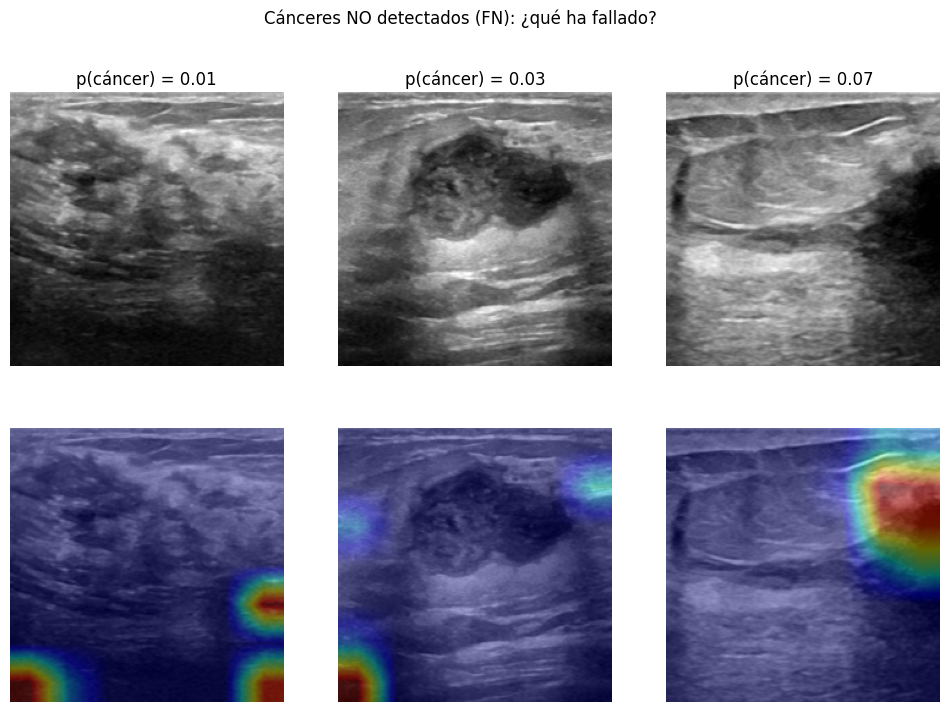

In [12]:
fn_idx = np.where((ys == 1) & (probs < umbral_clin))[0]
print("Cánceres no detectados:", len(fn_idx), "| sus probabilidades:", probs[fn_idx].round(3))
show_cam(fn_idx, "Cánceres NO detectados (FN): ¿qué ha fallado?")

## Explainability (Grad-CAM) & error analysis
- **Correctly detected cancers:** Grad-CAM highlights the lesion itself, suggesting the model relies on relevant features rather than spurious ones (e.g., text, corners).
- **Missed cancers (3/42), all with very low predicted probability (0.008–0.071):**
  1. No clearly visible lesion: no evidence found anywhere in the image.
  2. Malignant lesion with benign-looking features (posterior acoustic enhancement): a known diagnostic mimic.
  3. Lesion at the image border, partially cut off: likely under-represented, as training lesions are mostly centred.
- **Next steps:** translation augmentation (reduce centre bias), more hard cases and higher-resolution images.
- *Technical notes:* Grad-CAM was applied to the final ReLU via a wrapper (torchvision uses an in-place ReLU that breaks hooks), with custom min-max normalisation (MONAI's default normaliser inverts the map). Grad-CAM gives coarse (7×7) localisation and always rescales to [0, 1], so weak maps can still show "red" areas.